In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
file_path = '../data/processed/inc5000_2014_clean.csv'

df = pd.read_csv(file_path)

df_clean = df.copy()

print(df_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           5000 non-null   int64  
 1   rank         5000 non-null   int64  
 2   workers      4987 non-null   float64
 3   company      5000 non-null   str    
 4   url          5000 non-null   str    
 5   state_l      5000 non-null   str    
 6   state_s      5000 non-null   str    
 7   city         5000 non-null   str    
 8   metro        4942 non-null   str    
 9   growth       5000 non-null   float64
 10  revenue      5000 non-null   int64  
 11  industry     5000 non-null   str    
 12  yrs_on_list  5000 non-null   int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 507.9 KB
None


Área	       Pregunta que queremos responder
Crecimiento	   ¿Qué empresas presentan los mayores porcentajes de crecimiento?
Ingresos	   ¿Qué empresas generan mayores ingresos?
Empleo	       ¿Qué empresas tienen más trabajadores?
Eficiencia	   ¿Qué relación existe entre ingresos y cantidad de trabajadores?

In [ ]:
#Ingresos: ¿Qué empresas generan mayores ingresos?

hightest_revenue = df.nlargest(10, 'revenue') [
    ['company', 'industry', 'revenue']
].sort_values('revenue', ascending=False)

hightest_revenue


,company,industry,revenue
2662,Pacific Union Real Estate,Real Estate,5528202691
4949,ABC Supply,Construction,4911166514
3690,Eco-Energy Global Biofuels,Energy,4138790000
1982,EnvisionRxOptions,Health,3644869906
256,Bridger,Energy,3487872233
4618,Prime Therapeutics,Health,2511716640
4203,Flyers Energy,Energy,1977921907
3425,Sun Coast Resources,Energy,1868964476
3240,Carahsoft Technology,Government Services,1724988401
3820,TriNet,Human Resources,1644275000


In [92]:
#Empleo: ¿Qué empresas tienen más trabajadores?
most_workers = df.nlargest(10, 'workers') [
    ['company', 'industry', 'revenue', 'workers']
].sort_values('workers', ascending=False)

most_workers

,company,industry,revenue,workers
2304,Universal Services of America,Security,802076555,34219.0
4151,Sutherland Global Services,Business Products & Services,771259000,30000.0
4176,The Seaton Companies,Human Resources,587299000,28726.0
4506,AtWork Group,Human Resources,132359522,23689.0
4222,Infiniti HR,Human Resources,151039927,20000.0
4676,United Service Companies,Business Products & Services,135493184,13100.0
4301,Wingstop,Food & Beverage,549910831,12500.0
2734,Insight Global,IT Services,918390882,11561.0
4575,VXI Global Solutions,Telecommunications,249609092,10000.0
4128,Acro Service,Human Resources,215367840,9546.0


In [ ]:
#business growth. Which are the 10 growthest business? 
top_growth = df_clean.nlargest(10, "growth")[
    ["company", "industry", "growth", "revenue", "workers"]
]

top_growth

,company,industry,growth,revenue,workers
0,Fuhu,Consumer Products & Services,158956.9106,195640000,227.0
1,Quest Nutrition,Food & Beverage,57347.9246,82640563,191.0
2,Reliant Asset Management,Business Products & Services,55460.1646,85076502,145.0
3,Superfish,Software,26042.9630,35293000,62.0
4,Acacia Communications,Telecommunications,20690.4578,77652360,92.0
5,Provider Power,Energy,19876.5169,137977203,50.0
6,Crescendo Bioscience,Health,18375.0693,27308000,129.0
7,Plexus Worldwide,Health,16457.6529,159897088,130.0
8,Vacasa,Travel & Hospitality,16192.0610,26263454,264.0
9,Go Energies,Energy,16006.8013,32851754,11.0


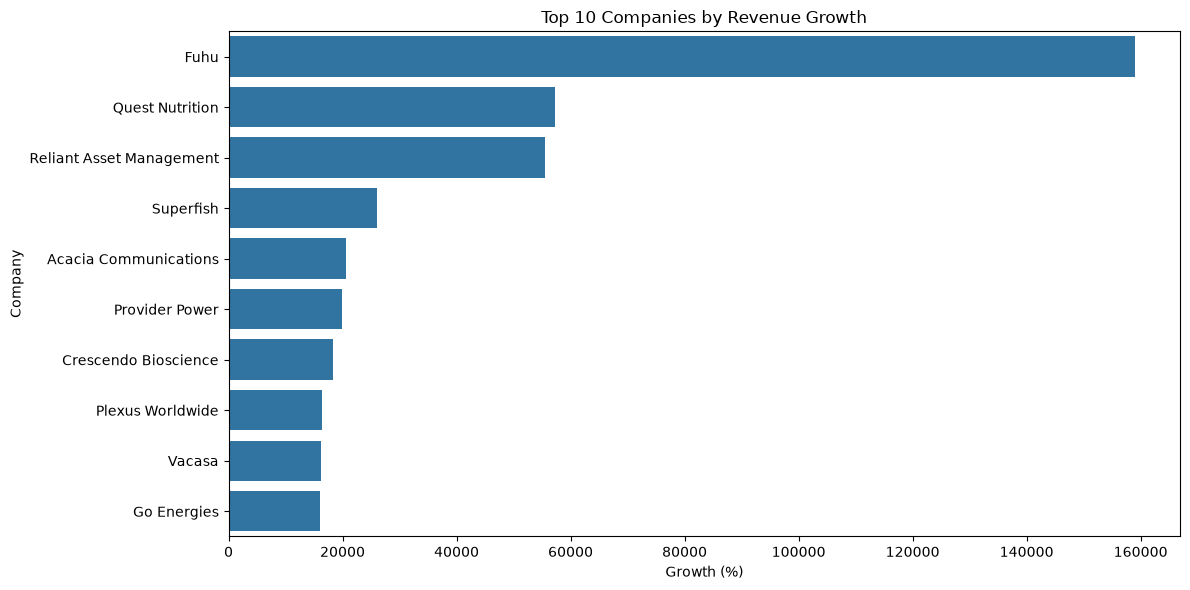

In [12]:
#gráfico para comparar
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_growth,
    x='growth',
    y='company'
)

plt.title('Top 10 Companies by Revenue Growth')
plt.xlabel("Growth (%)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

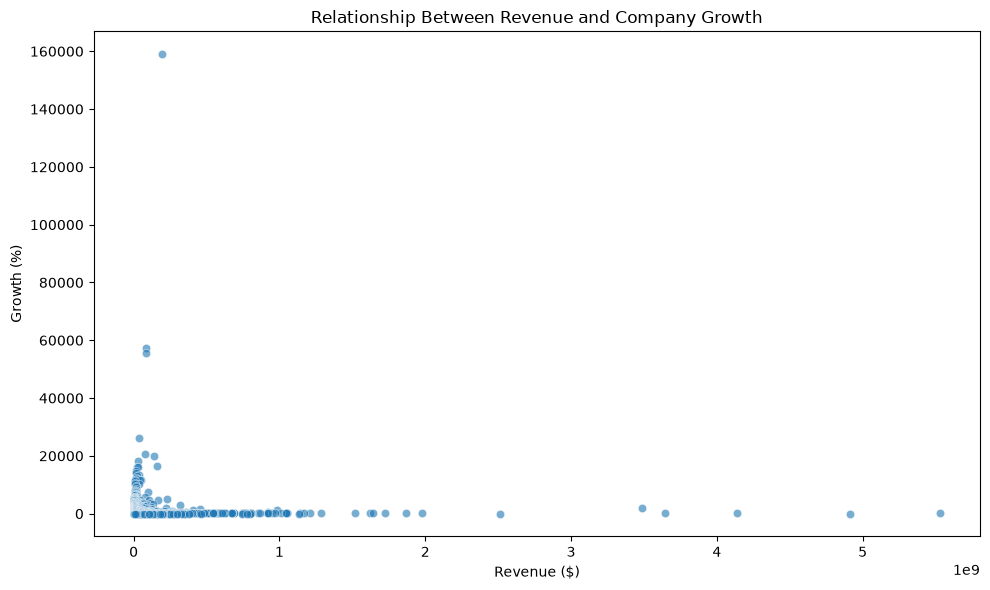

In [13]:
#growth vs revenue

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="revenue",
    y="growth",
    alpha=0.6
)

plt.title("Relationship Between Revenue and Company Growth")
plt.xlabel("Revenue ($)")
plt.ylabel("Growth (%)")

plt.tight_layout()
plt.show()

In [14]:
#correlacion entre ganancia y crecimiento
correlation = df_clean["revenue"].corr(df_clean["growth"])

print(f"Revenue-Growth Correlation: {correlation:.4f}")

Revenue-Growth Correlation: 0.0017


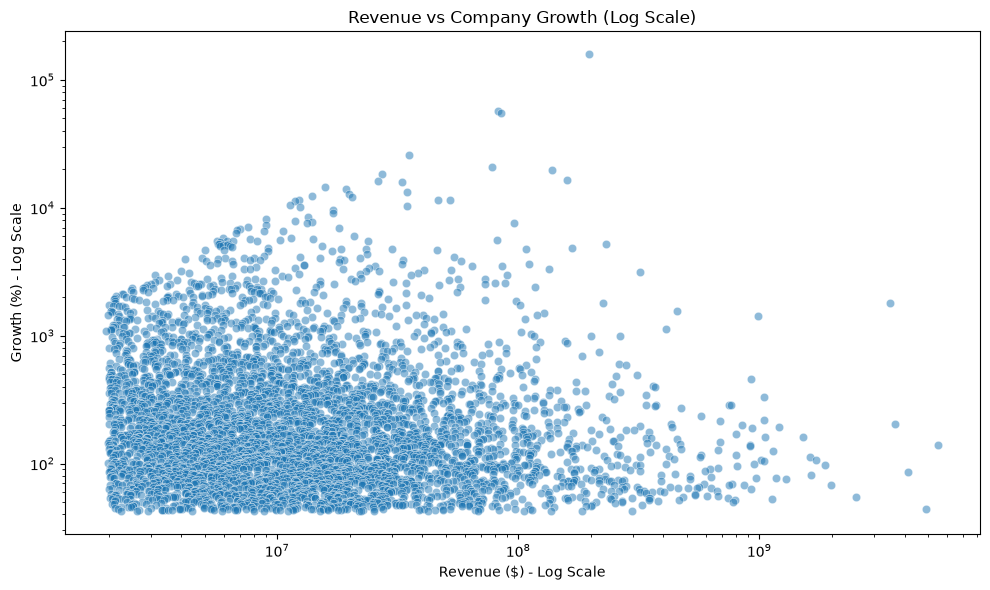

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="revenue",
    y="growth",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.title("Revenue vs Company Growth (Log Scale)")
plt.xlabel("Revenue ($) - Log Scale")
plt.ylabel("Growth (%) - Log Scale")

plt.tight_layout()
plt.show()

El análisis de correlación entre los ingresos y el crecimiento de las empresas obtuvo un coeficiente de Pearson de 0.0017, lo que evidencia una relación lineal prácticamente inexistente entre ambas variables. Esto sugiere que las empresas con mayores ingresos no necesariamente presentan mayores porcentajes de crecimiento. Por lo tanto, el tamaño de los ingresos y la velocidad de crecimiento representan dimensiones diferentes del desempeño empresarial.

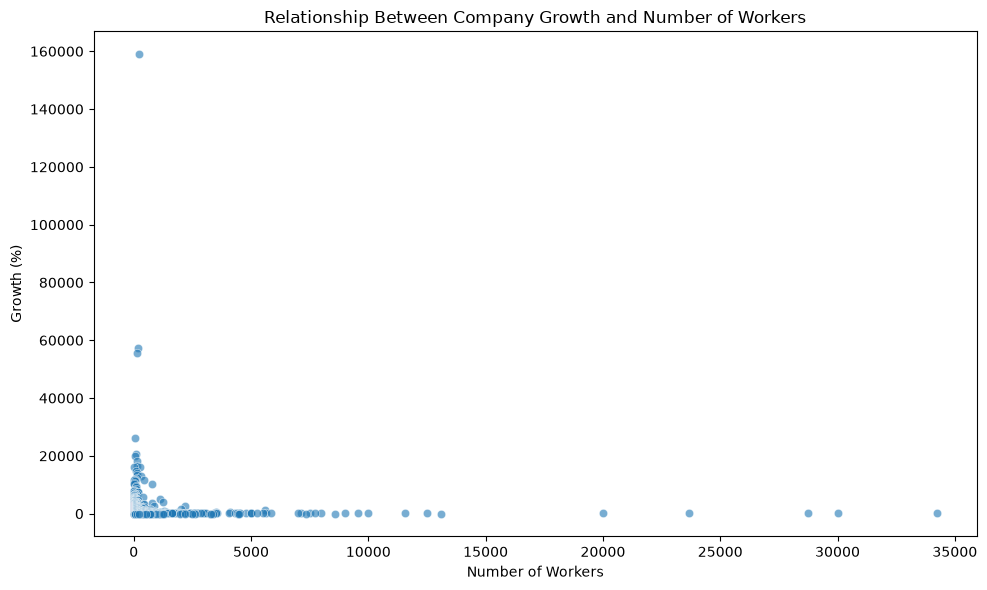

In [ ]:
#There are a relation between growth and number of workers in an enterprise?
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="workers",
    y="growth",
    alpha=0.6
)

plt.title("Relationship Between Company Growth and Number of Workers")
plt.xlabel("Number of Workers")
plt.ylabel("Growth (%)")

plt.tight_layout()
plt.show()

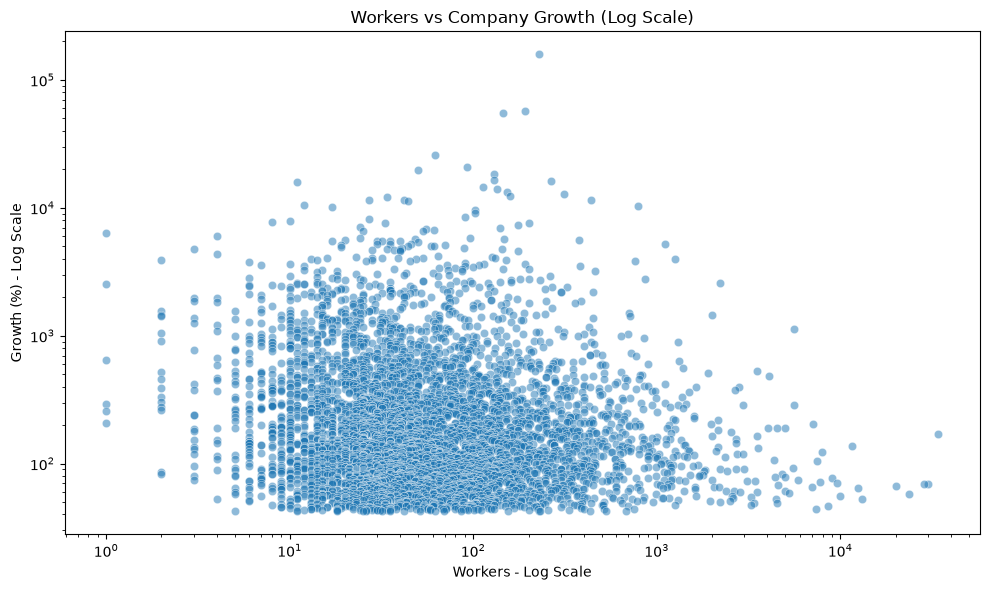


Workers-Growth Correlation: -0.0126


In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="workers",
    y="growth",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.title("Workers vs Company Growth (Log Scale)")
plt.xlabel("Workers - Log Scale")
plt.ylabel("Growth (%) - Log Scale")

plt.tight_layout()
plt.show()


#correlacion - Pearson
correlation = df_clean["workers"].corr(df_clean["growth"])

print(f'\nWorkers-Growth Correlation: {correlation:.4f}')

In [32]:
#analizar si existen diferencias importantes en el crecimiento promedio entre las industrias
industry_growth = df_clean.groupby('industry')['growth'].agg(
    ['count', 'mean', 'median']).sort_values('mean', ascending=False)

industry_growth

,count,mean,median
industry,,,
Consumer Products & Services,230,1331.791067,198.63470
Energy,116,970.035263,193.12880
Food & Beverage,132,963.141847,176.53955
Health,377,637.632964,169.34860
Government Services,212,594.710256,218.95655
Real Estate,131,576.903832,198.73960
Financial Services,278,572.454370,159.22720
Software,338,557.109204,207.76595
Travel & Hospitality,62,547.304384,120.99940


Consumer Products & Services presentó el mayor crecimiento promedio entre las industrias analizadas, con un 1,331.79 %, seguido de Energy, con un 970.04 %, y Food & Beverage, con un 963.14 %. Sin embargo, al comparar las medianas, se observa que el crecimiento típico de Consumer Products & Services fue de 198.63 %. Esta diferencia evidencia la influencia de valores extremos sobre el promedio y demuestra la importancia de utilizar medidas estadísticas complementarias para interpretar los resultados.

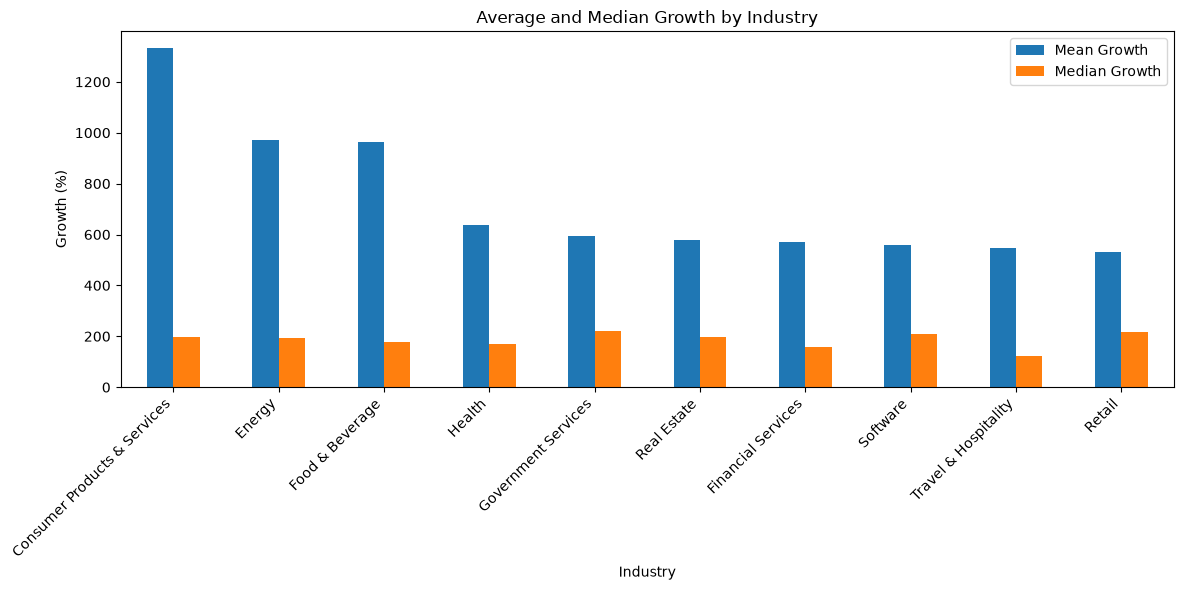

In [36]:
#grafico
industry_growth_plot = industry_growth.sort_values(
    "mean", ascending=False
).head(10)

industry_growth_plot[["mean", "median"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average and Median Growth by Industry")
plt.xlabel("Industry")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Mean Growth", "Median Growth"])
plt.tight_layout()
plt.show()


la cantidad de trabajadores no presenta una relación lineal significativa con el crecimiento de las empresas analizadas.

In [64]:
#¿En qué estados de Estados Unidos se concentra la mayor cantidad de empresas del Inc. 5000 de 2014?
bussines_amount = df_clean.groupby('state_l')['company'].agg(
    ['count']).sort_values(by='count', ascending=False)

porcent = []

for number in bussines_amount['count']:
    porc = (number * 100) / 5000
    porcent.append(porc)

bussines_amount['percentage'] = porcent
    
bussines_amount

,count,percentage
state_l,,
California,694,13.88
Texas,404,8.08
New York,335,6.70
Florida,303,6.06
Virginia,284,5.68
Illinois,238,4.76
Georgia,209,4.18
Pennsylvania,191,3.82
Massachusetts,174,3.48


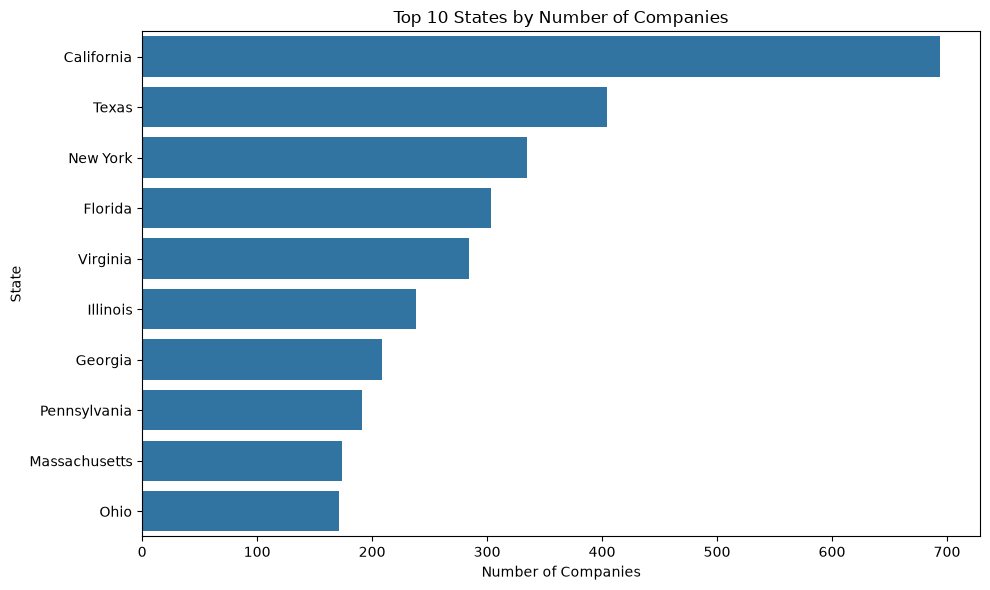

In [65]:
#grafico 
top_states = df_clean["state_l"].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_states.values,
    y=top_states.index
)

plt.title("Top 10 States by Number of Companies")
plt.xlabel("Number of Companies")
plt.ylabel("State")

plt.tight_layout()
plt.show()